# [실습1] 연료에 따른 자동차의 이동 거리 예측 모델 최적화

### 1. 데이터 준비

| fuel | distance |
| ---- | ------- |
| 4    | 6       |
| 8    | 5       |
| 12   | 15      |
| 16   | 12      |
| 20   | 20      |


In [27]:
import numpy as np
#연료에 대한 자동차의 이동 거리 데이터
car = [[ 4,  6],
       [ 8,  5],
       [12, 15],
       [16, 12],
       [20, 20]]

car = np.array(car)
print(car)

[[ 4  6]
 [ 8  5]
 [12 15]
 [16 12]
 [20 20]]


In [28]:
#데이터 추출
X = car[:, 0] #fuel
y = car[:, 1] #distance
print(X)
print(y)

[ 4  8 12 16 20]
[ 6  5 15 12 20]


### 2. 연료에 대한 이동 거리 사이의 관계 시각화

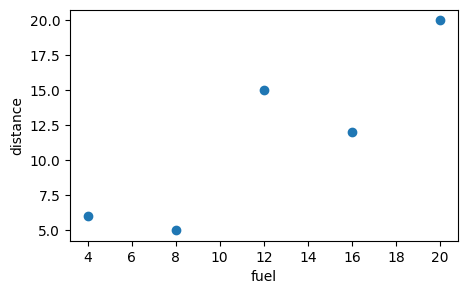

In [29]:
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [5, 3] # [width, height] (inches)

plt.scatter(X, y)

plt.xlabel("fuel")
plt.ylabel("distance")
plt.show()

### 3. 연료 변화에 따른 이동 거리 예측 모델 1, 2

In [30]:
# 연료에 대한 거리를 예측하는 선, 예측선(Prediction Line), y=aX
# 예측 모델 함수 정의: 주어진 연료(X)와 가중치(w)로 거리(y)를 추정
# ==========================
# 예측 함수 Ŷ = w * X
# ==========================
def pred_func(X, w):
    '''y=aX 모델에서 a는 가중치(w)이다.'''
    return w * X

In [31]:
#a값을 임의로 설정
a1 = (9/8)
a2 = (7/8)

# 예측값(y_pred) 계산
y_pred_1 = pred_func(X, a1) #모델 1 : y=(9/8)*x, a 값을 (9/8)로 설정
y_pred_2 = pred_func(X, a2) #모델 2 : y=(7/8)*x, a 값을 (7/8)로 설정
print(y_pred_1)
print(y_pred_2)

[ 4.5  9.  13.5 18.  22.5]
[ 3.5  7.  10.5 14.  17.5]


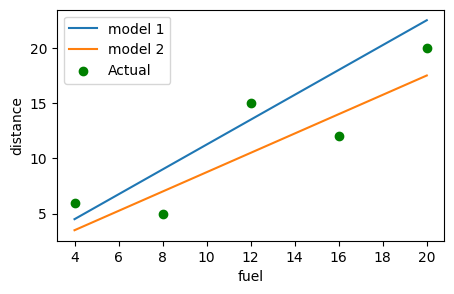

In [32]:
#모델 1, 2 시각화
plt.plot(X, y_pred_1, label="model 1")
plt.plot(X, y_pred_2, label="model 2")
plt.scatter(X, y, c="g", label="Actual")
plt.xlabel("fuel")
plt.ylabel("distance")
plt.legend()
plt.show()

기울기가 다른 두 모델을 비교해 보자. 모델 1은 a = 9/8, 모델 2는 a = 7/8이다.<br>
그래프만 보고는 어느 모델이 더 나은지 판단하기 어렵다.

# **어떤 모델이 더 정확한가?** <br>
두 모델의 **오차(실제값-예측값)** 를 비교하여, 오차가 더 작은 모델이 **더 정확한 예측**을 한다.


| fuel(X) | distance(y) | 모델1 예측 | 모델1 오차 | 모델2 예측 | 모델2 오차 |
|-------|--------------|----------------------|--------------|----------------------|--------------|
| 4     | 6            | 4.5                  | 1.5          | 3.5                  | 2.5          |
| 8     | 5            | 9.0                  | -4.0         | 7.0                  | -2.0         |
| 12    | 15           | 13.5                 | 1.5          | 10.5                 | 4.5          |
| 16    | 12           | 18.0                 | -6.0         | 14.0                 | -2.0         |
| 20    | 20           | 22.5                 | -2.5         | 17.5                 | 2.5          |


=> 각 데이터의 오차만으로 전체 모델의 성능을 판단하기 어렵다. <br>
데이터가 여러 개일 때는 모든 오차를 종합해 모델의 성능을 평가해야 한다. <br>
이때 사용하는 것이 **손실 함수**이다.

## **손실 함수(Loss Function)**
- 모델의 예측값과 실제값의 차이를 하나의 숫자로 나타내 모델의 성능을 평가하는 함수이다.
- 손실이 작을수록 좋은 모델이며, 모델은 이 값을 줄이는 방향으로 학습한다.
- 손실 함수 종류 : 평균제곱오차(MSE), 교차 엔트로피(Cross-Entropy) 등


<table><tr><td>
<font size=2>
회귀 문제(Regression Problem)<br>
- 연속적인 값을 예측하는 과제를 다룬다.<br>
- 입력 데이터와 출력 데이터 간의 관계를 모델링하고, 입력이 주어졌을 때 연속적인 출력 값을 예측하는 것이 목표가 된다.<br>
- 예를 들어, 집의 크기·위치·건축 연도 등의 특성을 사용하여 주택 가격을 예측하는 문제가 회귀 문제의 대표적인 예시가 된다.<br>
- 회귀 모델은 주로 평균제곱오차(Mean Squared Error, MSE)와 같은 손실 함수를 사용하여, 예측값과 실제값 사이의 차이를 최소화하도록 학습된다.
</font><p>
<font size=2>
분류 문제(Classification Problem)<br>
- 입력 데이터를 미리 정의된 클래스나 범주로 구분하는 과제를 다룬다.<br>
- 주어진 입력이 어떤 범주에 속하는지를 예측하는 것이 목표가 된다.<br>
- 예를 들어, 이메일 메시지가 “스팸”인지 “스팸 아님”인지를 구분하는 것이 분류 문제의 한 예가 된다.<br>
- 분류 모델은 주로 교차 엔트로피 손실(Cross-Entropy Loss)과 같은 손실 함수를 사용하여, 예측 결과와 실제 레이블 간의 차이를 최소화하도록 학습된다.
</font>
</td></tr></table>

### **MSE(Mean Square Error, 평균제곱오차)**<br>
- 주로 회귀(Regression) 문제에서 사용
- 예측값과 실제값의 차이(오차)를 제곱한 후, 그 값들의 평균을 구하는 방식
  - 오차가 '+' 인지 '-' 인지 중요하지 않다. 얼마나 틀렸는지가 중요하다 → 그래서 제곱
  - 데이터가 여러 개 있으니 전체적으로 얼마나 틀렸는지 하나의 숫자로 표시 → 평균
- 오차를 제곱하므로, 큰 오차에 더 큰 패널티를 부여
- MSE 값이 0에 가까울수록 예측 오차가 작아 모델의 예측 성능이 좋다.

<table><tr><td>
<img src="https://velog.velcdn.com/images/parkjunsu3321/post/fb2389e2-d2b8-4004-a9df-44ef87bea845/image.png" width=300></td>
<td>

<ul>
<li> 오차: 데이터마다 실제값 − 예측값을 계산한다. <br>
<li> 제곱: 오차가 +인지 −인지보다 얼마나 틀렸는지가 중요하다. <br> 제곱하면 모두 양수가 되어 서로 상쇄되지 않고, 큰 오차에 더 큰 벌점이 붙는다.<br>
<li> 평균: 데이터가 여러 개이므로 전체적으로 얼마나 틀렸는지를 하나의 숫자로 정리한다.
</ul>
</td>
</tr>
</table>
<b> → MSE가 0에 가까울수록 예측값이 실제값에 가깝다. 즉, 오차가 작은 좋은 모델이다. </b>

### 손실 함수 MSE 구현

In [7]:
print(np.square([2, 3, 4]))

[ 4  9 16]


In [8]:
e = y - y_pred_1
print("오차", e)
se = np.square(e)
print("제곱오차", se)

mse = np.mean(se) #np.mean(제곱 오차 배열)
print("평균제곱오차", mse)

오차 [ 1.5 -4.   1.5 -6.  -2.5]
제곱오차 [ 2.25 16.    2.25 36.    6.25]
평균제곱오차 12.55


In [9]:
mse_1 = np.mean(np.square(y - y_pred_1))
print("모델 1의 평균제곱오차", mse_1)

mse_2 = np.mean(np.square(y - y_pred_2))
print("모델 2의 평균제곱오차", mse_2)

모델 1의 평균제곱오차 12.55
모델 2의 평균제곱오차 8.15


In [10]:
# ==========================
# 손실 함수 (MSE)
# ==========================
def mse(y_true, y_pred):
    return np.mean(np.square(y_true - y_pred))

print("모델 1의 평균제곱오차", mse(y, y_pred_1))
print("모델 2의 평균제곱오차", mse(y, y_pred_2))

모델 1의 평균제곱오차 12.55
모델 2의 평균제곱오차 8.15


### 4. 연료에 따른 자동차의 이동 거리 예측 모델을 손실 함수로 평가하기

In [11]:
# 전체 코드

import numpy as np
#연료에 대한 자동차의 이동 거리 데이터
car = [[ 4,  6],
       [ 8,  5],
       [12, 15],
       [16, 12],
       [20, 20]]

car = np.array(car)

#데이터 추출
X = car[:, 0] #fuel
y = car[:, 1] #distance

# ==========================
# 예측 함수 Ŷ = w * X
# ==========================
def pred_func(X, w):
    '''y=aX 모델에서 a는 가중치(w)이다.'''
    return w * X


#a값을 임의로 설정
a1 = (9/8)
a2 = (7/8)

# 예측값(y_pred) 계산
y_pred_1 = pred_func(X, a1) #모델 1 : y=(9/8)*x, a 값을 (9/8)로 설정
y_pred_2 = pred_func(X, a2) #모델 2 : y=(7/8)*x, a 값을 (7/8)로 설정

# ==========================
# 손실 함수 (MSE)
# ==========================
def mse(y_true, y_pred):
    return np.mean(np.square(y_true - y_pred))

print("모델 1의 평균제곱오차", mse(y, y_pred_1))
print("모델 2의 평균제곱오차", mse(y, y_pred_2))

모델 1의 평균제곱오차 12.55
모델 2의 평균제곱오차 8.15


자신이 찾은 a값을 사용한 예측모델의 MSE(평균제곱오차)를 구해보자.

In [12]:
a = 0.95
y_pred = pred_func(X, a)
print(f"나의 모델의 평균제곱오차 {mse(y, y_pred):.2f}")

나의 모델의 평균제곱오차 7.16


#[실습 2] **기온에 따른 아이스크림 판매 수익 예측 모델 최적화**

### 0. 드라이브 마운트
Google Colab 환경에서 Google 드라이브를 마운트


방법 1
- Google Colab 환경에서 Google 드라이브를 마운트하는 데 사용
- 왼쪽 메뉴 중 '폴더' 모양 선택 - 히든 메뉴 나타나면 다시 '폴더(구글드라이브)' 모양 선택

방법 2

In [13]:
from google.colab import drive
# google.colab 모듈에서 drive라는 객체를 가져오는 것,
# drive는 Google Colab에서 Google 드라이브와 연동할 수 있게 해주는 도구

drive.mount('/content/drive/')
#Google 드라이브를 Colab 환경에 마운트하는 역할
#/content/drive/ 경로에 드라이브가 연결되어, 드라이브 내 파일에 접근하거나 파일을 읽고 쓸 수 있게 됩니다.
#실행 시 사용자에게 인증을 위한 링크가 제공되고, 인증 절차를 완료하면 드라이브가 마운트됩니다.
#이 코드는 Google 드라이브의 파일을 Colab 노트북에서 사용할 수 있도록 연결하는 과정입니다.

Mounted at /content/drive/


드라이브 연결 후, 코드 파일(.ipynb)이 있는 경로로 이동

In [14]:
cd /content/drive/MyDrive/Colab Notebooks

/content/drive/MyDrive/Colab Notebooks


파일 목록 확인

In [15]:
ls

 07_9_사용자_정의_함수_1_25101171_샤프린.ipynb          icecream.csv
'09_12_자동차 데이터 시각화_Colab.ipynb'                Untitled0.ipynb
'10_13_데이터_파일_활용_25101171_아흐멧 샤프린.ipynb'   Untitled1.ipynb
 11_15_최적화_손실함수.ipynb                            Week7.ipynb


### 1. 데이터 확인 및 전처리

In [16]:
import numpy as np
data = np.loadtxt('icecream.csv', delimiter=',', skiprows=1)

In [17]:
#데이터 확인
print(data.shape)
print(data[:5])

(365, 2)
[[39.   13.17]
 [40.   11.88]
 [41.   18.82]
 [42.   18.65]
 [43.   17.02]]


In [21]:
#데이터 추출
X = data[:, 0] #temperature
y = data[:, 1] #Profits
print(X.shape, X[:3])
print(y.shape, y[:3])

(365,) [39. 40. 41.]
(365,) [13.17 11.88 18.82]


In [22]:
# 화씨(°F)를 섭씨(°C)로 변환
# °C = (°F - 32) * 5/9
X = (X - 32) * 5/9
print(X[:3])

[3.88888889 4.44444444 5.        ]


### 2. 기온에 따른 아이스크림 판매 수익 예측 모델 시각화

y = aX 모델 만들기 및 시각화

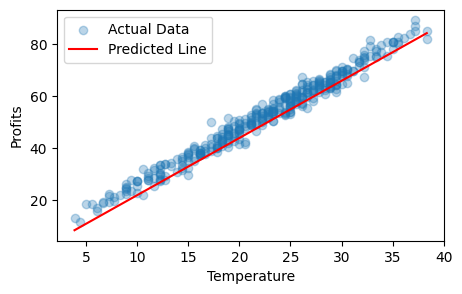

In [25]:
# ==========================
# 예측 함수 Ŷ = w * X
# ==========================
def pred_func(X, w):
    '''y=aX 모델에서 a는 가중치(w)이다.'''
    return w * X

#데이터를 잘 설명할 수 있는 a값을 찾아보자.
a = 2.2    # ? 작성

# 정의된 모델 함수를 사용하여 예측값(y_pred) 계산
y_pred = pred_func(X, a) # ? 작성

#데이터 및 예측 모델 시각화
import matplotlib.pyplot as plt
plt.scatter(X, y, label="Actual Data", alpha=0.3)
plt.plot(X, y_pred, "r", label="Predicted Line")
plt.xlabel("Temperature")
plt.ylabel("Profits")
plt.legend()


plt.show()

y = aX + b 모델 만들기 및 시각화 (bias 추가)

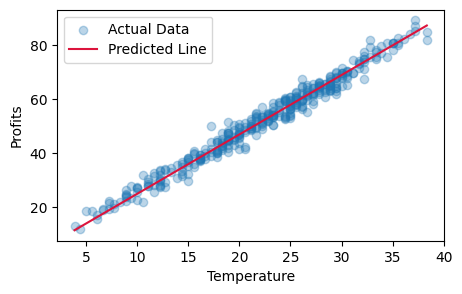

In [26]:
# ==========================
# 예측 함수 Ŷ = w * X + b
# ==========================
def pred_func(X, w, b):
    '''y=aX+b 모델에서 a는 가중치(w), b는 편향(bias)이다.'''
    return w * X + b

#데이터를 잘 설명할 수 있는 a, b값을 찾아보자.
a = 2.2    # ? 작성
b = 3    # ? 작성

# 정의된 모델 함수를 사용하여 예측값(y_pred) 계산
y_pred = pred_func(X, a, b) # ? 작성

#데이터 및 예측 모델 시각화
import matplotlib.pyplot as plt
plt.scatter(X, y, label="Actual Data", alpha=0.3)
plt.plot(X, y_pred, color="crimson", label="Predicted Line")
plt.xlabel("Temperature")
plt.ylabel("Profits")
plt.legend()


plt.show()

### MSE(평균제곱오차)를 활용한 모델 평가

 y = aX 모델 평가

In [34]:
# 전체 코드

import numpy as np
data = np.loadtxt('icecream.csv', delimiter=',', skiprows=1)

#데이터 추출 및 전처리
X = (data[:, 0] - 32) * 5/9 #temperature ? 작성
y = data[:, 1] #Profits ? 작성

# ==========================
# 예측 함수 Ŷ = w * X
# ==========================
def pred_func(X, w):
  return w * X # ? 작성


#자신이 찾은 a값을 설정
a = 2.21 # ? 작성


# 예측값(y_pred) 계산
y_pred = pred_func(X, a) #? 작성


# ==========================
# 손실 함수 (MSE)
# ==========================
# ? 작성
def mse(y_true, y_pred):
    return np.mean(np.square(y_true - y_pred))


print("나의 모델의 평균제곱오차", mse(y, y_pred))

나의 모델의 평균제곱오차 15.178297483510912


 y = aX+b 모델 평가

In [35]:
# 전체 코드

import numpy as np
data = np.loadtxt('icecream.csv', delimiter=',', skiprows=1)

#데이터 추출 및 전처리
X = (data[:, 0] - 32) * 5/9 #temperature ? 작성
y = data[:, 1] #Profits ? 작성


# ==========================
# 예측 함수 Ŷ = w * X + b
# ==========================
def pred_func(X, w, b):
  return w * X + b # ? 작성


#자신이 찾은 a, b값을 설정
a = 2.144  # ? 작성
b = 5.37 # ? 작성


# 예측값(y_pred) 계산
y_pred = pred_func(X, a, b) # ? 작성

# ==========================
# 손실 함수 (MSE)
# ==========================
#? # ? 작성
def mse(y_true, y_pred):
    return np.mean(np.square(y_true - y_pred))


print("나의 모델의 평균제곱오차", mse(y, y_pred))

나의 모델의 평균제곱오차 6.646098640284123
